# Synthèse de l'étude

Ce projet Python a été mené par Tangi Ravenel, Logan Chauvez et Rafaël Shirikyan. 

Il repose sur des données de note de film issues de platformes permettant à des utilisateurs de noter leurs films visionnés (IMDB, TMDB, letterboxd). Notre objectif est de réussir à trouver des corrélations entre succès commercial d'un film, la note des utilisateurs, le budget du film, la renommée de ses acteurs...

---


### Sommaire
 * [1 - À propos de la base de données](#section_1)
 * [2 - Etudes statistiques](#section_2)
    * [2.1 - Quels genres cinématographiques sont les plus rentables ?](#section_2_1)
      * [2.1.1 - Rentabilité par genre](#section_2_1_1)
      * [2.1.1 - Budget et recettes par genre](#section_2_1_2)

<a id='section_1'></a>
## 1 - À propos de la base de données :

Pour choisir notre base de données, nous avons dû prendre des platformes dont les données sont libres de droit. Letterboxd ne permet plus cela depuis récemment.
Nous nous sommes rabattus sur IMDB qui laisse en libre téléchargement beaucoup de ses données [ici](https://datasets.imdbws.com), avec la documentation [ici](https://data.imdb.com/non-commercial-datasets/).

Nous avons également utilisé l'API de TMDB (voir [la documentation](https://developer.themoviedb.org/docs/getting-started)).

Avoir deux notes de films différentes pourrait nous permettre de différencier les deux platformes pour prédire le succès commercial d'un film en fonction de sa note.
Nous avons gardé comme échantillon 10000 films aléatoire obtenue sur IMDB (on a directement accès au film imdb mais il faut faire appel à l'API pour ceux TMDB) : on garde uniquement les films de plus d'une heure pour éviter court-métrage, documentaire et autre. On filtre également sur le nombre de votes pour garder des films représentatifs.

En vue de mener à bien nos analyses, nous avons décidé de former une grande base de données à partir de toutes les sources de données que nous avons. Ainsi le fichier join.py nous permet de joindre les 10 000 obtenue sur TMDB ,les notes que ces films ont obtenues sur IMDB, mais aussi le cast des acteurs du film, le réalisateur et d'autre données présentes sur la base de données IMDB.

On vérifie la distribution des années de sortie de notre échantillon

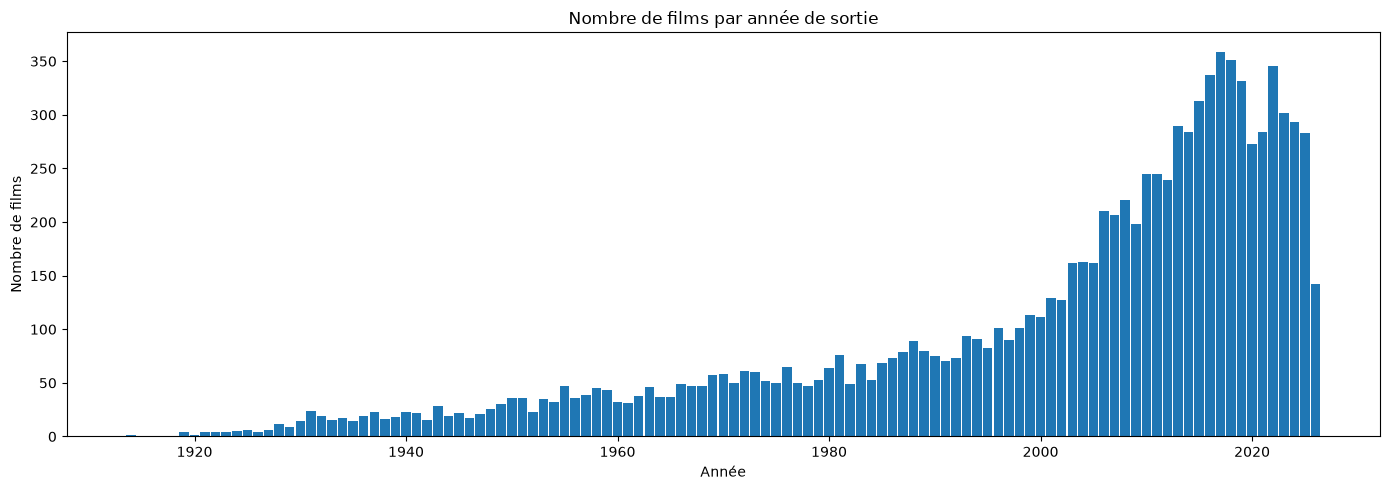

In [1]:
from Script.Description_base_de_donnee import *

films = pd.read_parquet("data/films_merged.parquet")
plot_films_par_annee(films)

On a beaucoup de film sortie récemment il faudra en prendre compte lors de nos analyses.

Films avec les deux notes : 9,903
Corrélation IMDb / TMDB : 0.821


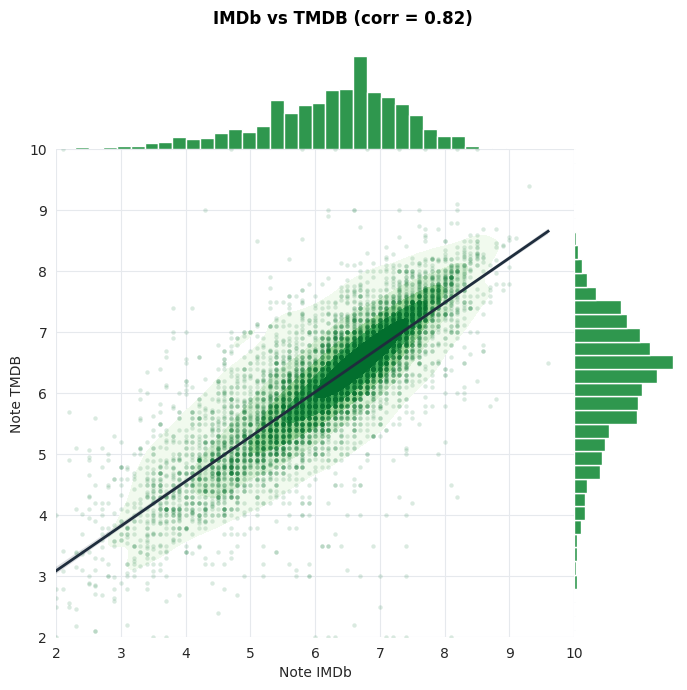

In [ ]:
plot_notes_imdb_tmdb(films)

On remarque que les deux notes sont très corrélés, ce qui était attendu. On pourra plus tard voir si dans nos analyse prendre en compte l'une ou l'autre note change la conclusion.

<a id='section_2'></a>
## 2 - Etudes statistiques

<a id='section_2_1'></a>
### 2.1 - Quels genres cinématographiques sont les plus rentables ?

<a id='section_2_1_1'></a>
### 2.1.1 - Rentabilité par genre

On se pose la question d'un lien entre genres cinématographiques d'un film et rentabilité (au sens du retour sur investissement). Quand on pense à un film dont les recettes sont importantes, on pense assez facilement à un *blockbuster* américain, le plus souvent un film d'action ; cependant ces films sont aussi ceux qui ont nécessité le plus gros budget de production. On peut faire la comparaison avec les films d'horreur, dont le budget de production peut être parfois très faible (par exemple, Paranormal Activity et ses $15 000 (!) de budget) mais dont le succès commercial peut être fulgurant.


On définit la rentabilité d'un film comme étant le rapport $\text{ROI} = \frac {\text{revenu}} {\text{budget}}$. On applique plusieurs contraintes pour l'étude statistique de ce phénomène :
 * On ne considère que les genres cinématographiques suffisament représentés. Cela permet de réaliser des agrégations de données pour un même genre cinématographique, de sorte que l'on puisse raisonnablement interpréter ces données. Le seuil choisi est `MIN_FILMS = 30`.
 * On ne considère que les films dont le budget dépasse un certain seuil. Cela évite l'écueil de la division par zéro dans la définition de la rentabilité, et cela permet aussi de filtrer des films dont le budget aurait pu être mal renseigné. Le seuil choisi est `MIN_BUDGET = 10000`.

Pour chaque genre de film répertorié dans la base de données, on calcule sa rentabilité moyenne ainsi que sa rentabilité médiane. On prend la rentabilité médiane comme principal indicateur, la distribution des rentabilités par genre pouvant être assez large et déséquilibrée et laissant peu de place à l'interprétation.

On crée un graphique *ridgeline* représentant chaque distribution de rentabilité par genre, ordonnée par rentabilité médiane. Plusieurs choix esthétiques :
 * Les densités sont représentées sur une échelle logarithmique : cela a pour effet de compresser les distributions et de les rendre plus facile à visualiser. 
 * Les distributions sont tracées avec un KDE de *bandwidth* `BW_ADJUST = 0.3`. La valeur a été choisie afin de lisser des irrégularités fortes dans les distributions.

On a de plus fait le choix de représenter des points correspondant à des films importants ou connus de l'histoire du cinéma, en vue de donner au lecteur un point d'ancrage lors de l'interprétation du graphique.

                    n  roi_median  roi_moyen
genres_TMDB                                 
History           128        1.15       1.96
Drama            1157        1.35       3.82
Crime             378        1.38       3.26
Mystery           182        1.45      97.32
War                94        1.49       4.09
Thriller          579        1.52       3.62
Western            39        1.58       2.48
Music              99        1.62       3.30
Science Fiction   238        1.84       4.79
Action            520        1.86       3.98
Fantasy           250        1.87       5.34
Romance           457        1.88       3.79
Comedy            835        1.96       8.91
Family            231        1.98       4.39
Adventure         378        2.10       4.48
Horror            270        2.19      68.89
Animation         132        2.20       7.30


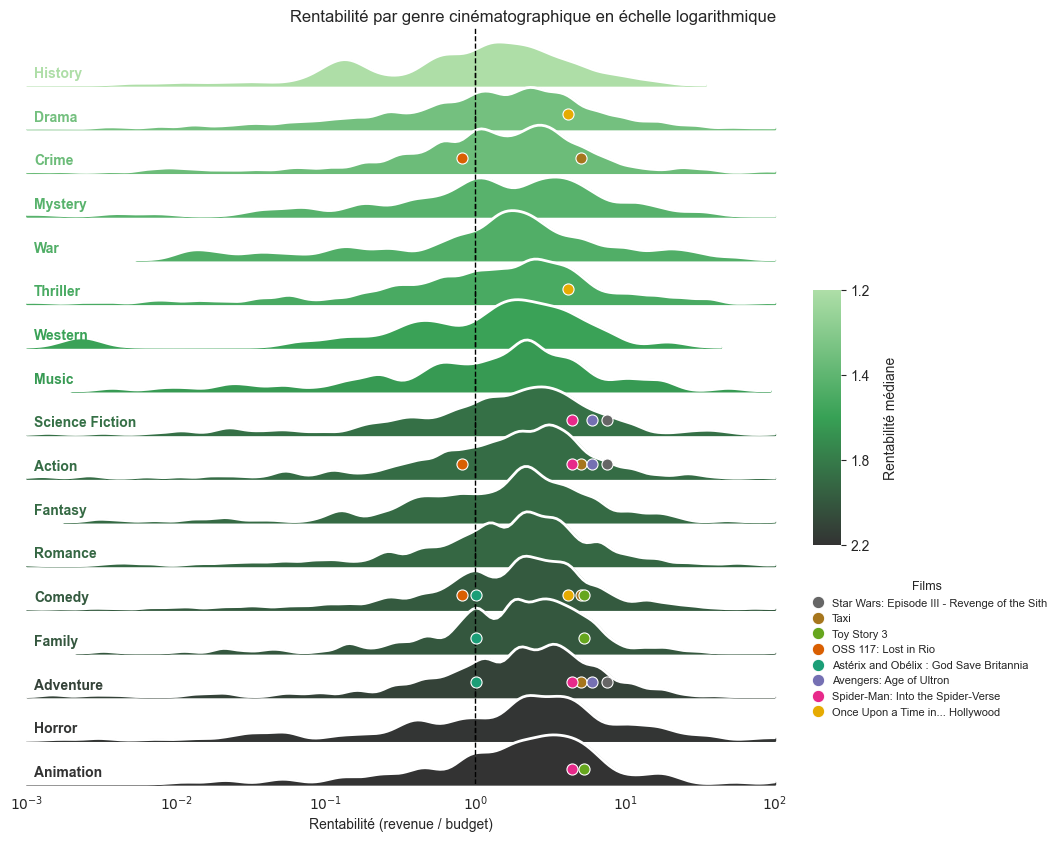

In [3]:
from Script import roi_by_genre

roi_by_genre.main()

Remarquons tout d'abord que les distributions, bien qu'elles soient assez irrégulières, présentent toutes une masse importante située au niveau d'une rentabilité supérieure à 1. On peut voir ce phénomène comme indicateur du simple fait qu'un film fortement noté est un film vu de beaucoup de gens, et donc généralement un film qui a généré beaucoup de recettes. Cela illustre un biais potentiel au niveau du choix des films que nous avons décidé de considérer dans la base de données ; nous estimons cependant que la plupart des films n'étant pas rentables sont rares, et sont généralement des films qui sont restés inconnus du grand public, ce qui les rendraient difficiles à étudier.

Le genre de film le plus rentable selon la médiane est le genre des films d'animation, avec une rentabilité médiane de 2,20. Plus généralement, les cinq genres les plus rentables sont Animation, Horreur, Aventure, Familial et Comédie. À l'exception du genre Horreur, ce sont par nature des genres cinématographiques qui ciblent souvent des publics de tout âge : cette caractéristique "tous-publics" pourrait expliquer des recettes importantes, et donc une rentabilité importante si les budgets sont suffisamment faibles.

Le genre Horreur est sans doute le genre dont la distribution présente la queue la plus lourde à droite. Cela rejoint l'observation initiale selon laquelle nombre de films d'horreur sont réalisés à un budget faible, et parviennent à rencontrer un franc succès commercial. On remarquera par ailleurs qu'alors que le ROI médian pour ce genre est de 2,19, le ROI moyen est trente fois plus élevé à 68,89, soit vastement au delà des ROI moyens pour la plupart des autres genres cinématographiques. Le fait que cela ne représente qu'une queue de la distribution rappelle toutefois que ces succès commerciaux fulgurants ne sont pas systématiques, et la présence d'une queue lourde à gauche indique aussi que certains films d'horreur peuvent subir des échecs importants en termes de rentabilité.

En opposition, les cinq genres de film les moins rentables en médiane sont Histoire, Drame, Crime, Mystère et Guerre. On peut y voir l'observation opposée : ce sont des genres cinématographiques assez peu accessibles aux plus jeunes, car généralement violents ou présentant des thèmes matures et adultes. 

Remarquons que la distribution du genre Western est particulièrement irrégulière, présentant notamment une bosse à gauche : du fait du faible nombre de westerns captés dans l'échantillon de la base de données, il est difficile d'en faire une étude aussi approfondie que pour les autres genres.

Le genre Mystère est celui qui présente le ROI moyen le plus important, à 97,32. C'est à contraster avec son ROI médian qui n'est que de 1,45, soit parmi les plus bas de tous les genres. C'est l'existence de cas "pathologiques" comme celui-ci qui laisse penser que la médiane est une mesure plus représentative de la rentabilité d'un genre comparé à sa moyenne : il est possible que notre échantillon ait pu présenter quelques rares films excessivement rentables dans le genre Mystère, sans que ceux-ci n'aient d'importance pour caractériser la tendance générale que l'on observe sur les densités.

<a id='section_2_1_2'></a>
### 2.1.2 - Budget et recettes par genre

On s'intéresse à présent au budget et aux recettes par genre cinématographique. Ce qui motive ce choix est la situation hypothétique suivante : imaginons qu'un *blockbuster* dont le budget est d'un milliard de dollars, et dont la rentabilité est de 1,1. Un tel blockbuster reste alors très profitable, car il produit un bénéfice de 100 M$. On se doute d'autre part qu'un film avec un budget énorme n'a pas nécessairement vocation à être rentable selon la mesure précédente de rentabilité, mais en particulier d'être profitable et de générer beaucoup d'argent.

Nous nous penchons donc sur les détails qui constituent ce calcul, selon les mêmes hypothèses d'étude que pour la situation précédente. On trace un graphique en violons scindés en deux, montrant par genre les distributions lissées pour le budget et le revenu ramenées sur une échelle logarithmique. Notamment :
 * On a conservé `MIN_FILMS = 30`, `MIN_BUDGET = 10000`, `BW_ADJUST = 0.3`.
 * On a rajouté `MIN_REVENUE = 10000` plutôt que de considérer tous les revenus possibles, ce qui réhausse la valeur `roi_median`.
 * L'ordre du classement est fait sur la médiane des recettes par genre.

                    n  budget_median  revenue_median  roi_median
genres_TMDB                                                     
Drama            1143      8500000.0       9644124.0        1.37
Western            39     10000000.0      10000000.0        1.58
Music              99     10000000.0      12000000.0        1.62
Romance           457      9898623.0      12376625.0        1.88
Crime             372     12000000.0      13572146.0        1.42
History           125     16000000.0      13728450.0        1.17
War                94     14200000.0      13882248.5        1.49
Horror            266      6250000.0      14005416.0        2.22
Thriller          571     11000000.0      15065483.0        1.54
Comedy            833     12000000.0      18254702.0        1.96
Mystery           177     11000000.0      18999718.0        1.53
Science Fiction   236     20000000.0      23972012.5        1.89
Fantasy           249     20000000.0      26611650.0        1.87
Action            517    

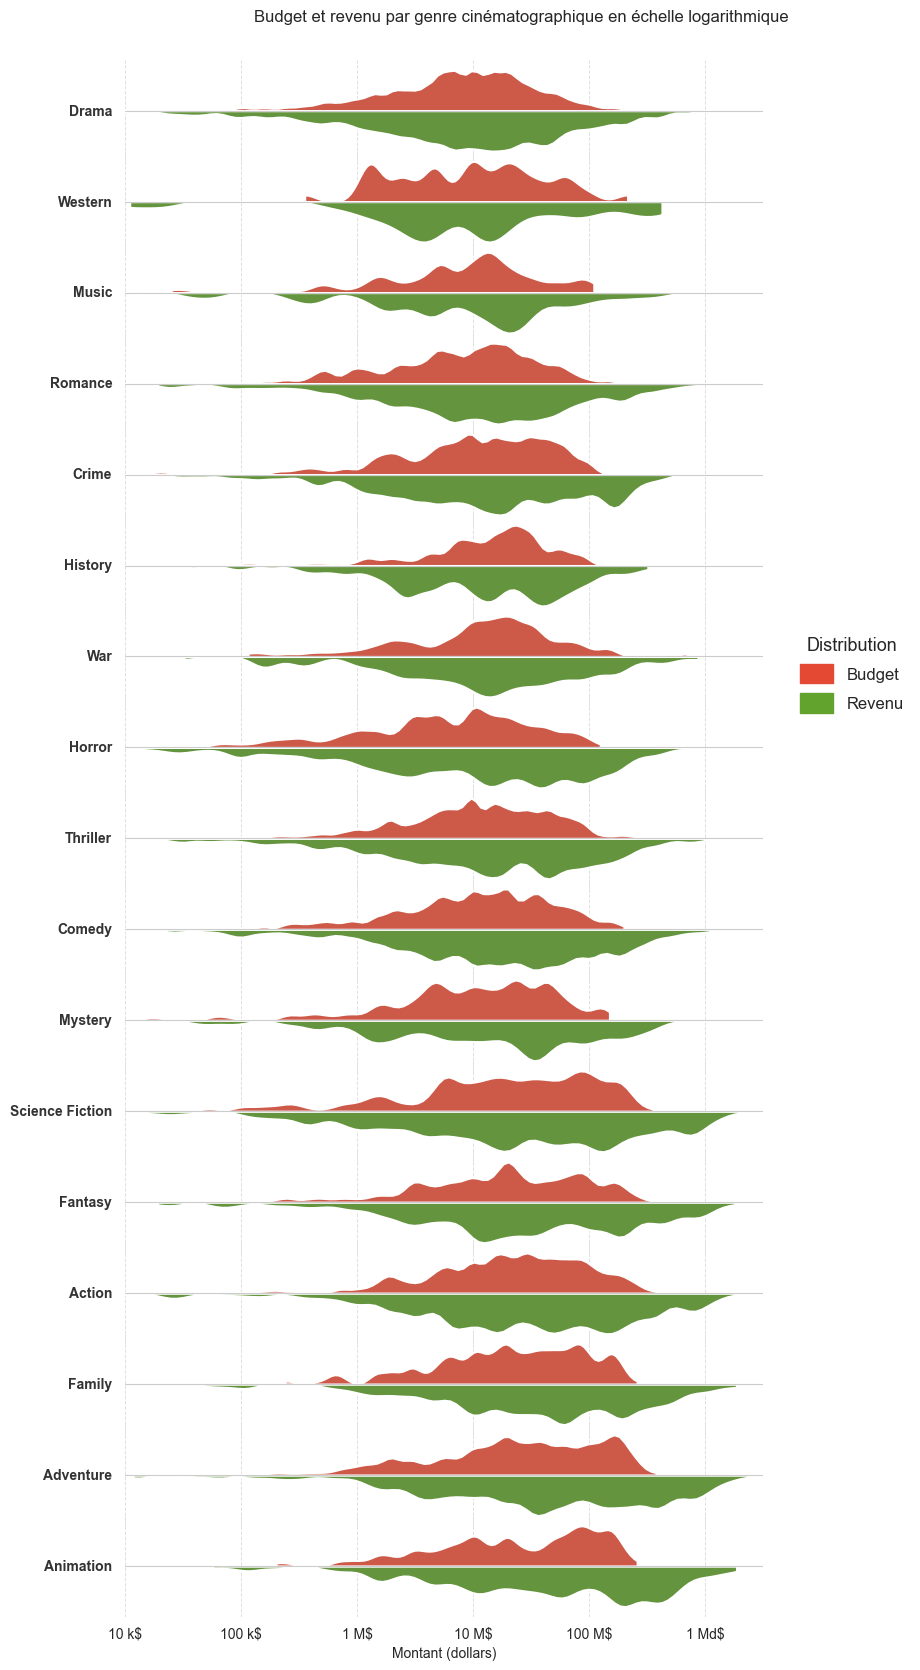

In [5]:
from Script import budget_revenue_by_genre

budget_revenue_by_genre.main()

Remarquons que le genre Animation reste en tête en ce qui concerne les recettes, suivi d'assez loin par les genres Aventure et Familial pour essentiellement les mêmes distributions de budget. (*à compléter*)